# Proyecto final: Todo modelo es un voto ponderado
**Análisis y Ciencia de Datos — UNIS**  ·  Grupo Bikeshare: Rodolfo Flores, Nohel Estrada, Humberto Najar

Casi todos los modelos del curso predicen como
$$\hat y(x) = \sum_{i=1}^n w_i(x)\, y_i .$$
En este notebook le sacamos los pesos a OLS, ridge, $k$-NN, un árbol y un *random forest*,
comprobamos que reproducen `.predict()`, medimos cuánta evidencia respalda cada predicción
y cuánto cuesta la flexibilidad. La Parte 1 usa California Housing y las Partes 2–4 usan Bikeshare.

Las funciones de pesos están en `pesos.py` (mismo directorio).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, mean_absolute_error, silhouette_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

import pesos as P

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
FIG = "../figuras"
RS = 0

## Preparación

### 0.1 Partición y estandarización
80/20 con `random_state=0`; el `StandardScaler` se ajusta **solo** con entrenamiento.

In [2]:
# California Housing (Parte 1)
cal = fetch_california_housing(as_frame=True)
Xc_raw_tr, Xc_raw_te, yc_tr, yc_te = train_test_split(cal.data, cal.target, test_size=0.2, random_state=RS)
esc_c = StandardScaler().fit(Xc_raw_tr)
Xc_tr, Xc_te = esc_c.transform(Xc_raw_tr), esc_c.transform(Xc_raw_te)
yc_tr, yc_te = yc_tr.to_numpy(), yc_te.to_numpy()
print("California:", Xc_tr.shape, Xc_te.shape)

California: (16512, 8) (4128, 8)


In [3]:
# Bikeshare (Partes 2 a 5)
bike = pd.read_csv("../data/Bikeshare.csv")
meses = {m: i + 1 for i, m in enumerate(["Jan", "Feb", "March", "April", "May", "June", "July",
                                         "Aug", "Sept", "Oct", "Nov", "Dec"])}
clima = {"clear": 1, "cloudy/misty": 2, "light rain/snow": 3, "heavy rain/snow": 4}
print("meses en el archivo:", bike.mnth.unique())
bike["mnth"] = bike["mnth"].map(meses)
bike["weathersit"] = bike["weathersit"].map(clima)
bike["hr"] = bike["hr"].astype(int)
assert bike[["mnth", "weathersit"]].notna().all().all()

VARS = ["day", "hr", "weekday", "workingday", "holiday", "temp", "hum", "windspeed", "mnth", "weathersit"]
Xb = bike[VARS].astype(float)
yb = np.log1p(bike["bikers"]).to_numpy()
Xb_raw_tr, Xb_raw_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, random_state=RS)
esc_b = StandardScaler().fit(Xb_raw_tr)
Xb_tr, Xb_te = esc_b.transform(Xb_raw_tr), esc_b.transform(Xb_raw_te)
bike_tr, bike_te = bike.loc[Xb_raw_tr.index], bike.loc[Xb_raw_te.index]
n_b = len(Xb_tr)
print("Bikeshare:", Xb_tr.shape, Xb_te.shape)

meses en el archivo: <StringArray>
['Jan', 'Feb', 'March', 'April', 'May', 'June', 'July', 'Aug', 'Sept', 'Oct', 'Nov', 'Dec']
Length: 12, dtype: str
Bikeshare: (6916, 10) (1729, 10)


### 0.2 Taiwan
No aplica a nuestro grupo (usamos Bikeshare), pero la idea es útil: si $w_i(x)\ge 0$ y $\sum_i w_i(x)=1$,
el voto ponderado de etiquetas 0/1 es un promedio convexo y queda en $[0,1]$. $k$-NN, el árbol y el bosque
cumplen esa condición; OLS y ridge suman 1 pero pueden tener pesos negativos.

### 0.3 ¿Por qué `casual` y `registered` no pueden ser variables?

In [4]:
print("¿casual + registered == bikers en todas las filas?",
      bool((bike.casual + bike.registered == bike.bikers).all()))

¿casual + registered == bikers en todas las filas? True


Porque son la respuesta partida en dos: `bikers = casual + registered` en el 100 % de las filas.
Usarlas sería *fuga de información* (target leakage): el modelo "predeciría" con la respuesta misma
y además, a la hora de usarlo (planear la reubicación de bicicletas por la mañana), esas cantidades
todavía no se conocen.

### 0.4 Desviación estándar antes de estandarizar
La guardamos en `desv_cruda`; la usamos en la Parte 4.

In [5]:
desv_cruda = Xb_raw_tr.std(ddof=0)
pd.DataFrame({"desv. estándar (entrenamiento, crudo)": desv_cruda,
              "media": Xb_raw_tr.mean()}).sort_values("desv. estándar (entrenamiento, crudo)", ascending=False)

,"desv. estándar (entrenamiento, crudo)",media
day,104.9296,184.6666
hr,6.8997,11.5759
mnth,3.4313,6.5805
weekday,2.0025,2.9935
weathersit,0.6549,1.4377
workingday,0.4649,0.6841
temp,0.1978,0.4894
hum,0.1968,0.6434
holiday,0.1668,0.0286
windspeed,0.1227,0.1904


---
## Parte 1: Los pesos de cinco modelos (California)

Si $\hat y(x)=\sum_i w_i(x) y_i$, en los puntos de entrenamiento $\hat{\mathbf y} = S\mathbf y$ con $S_{ij}=w_j(x_i)$.

### 1.1 OLS
$\hat\beta = (\tilde X^\top\tilde X)^{-1}\tilde X^\top \mathbf y$, entonces
$\hat y(x) = \tilde x^\top\hat\beta = \underbrace{\tilde x^\top (\tilde X^\top\tilde X)^{-1}\tilde X^\top}_{w(x)^\top}\mathbf y$.

**Suma de pesos.** $\sum_i w_i(x) = w(x)^\top\mathbf 1$. Como $\mathbf 1$ es la primera columna de $\tilde X$,
$\mathbf 1 = \tilde X e_1$ y
$$w(x)^\top \mathbf 1 = \tilde x^\top (\tilde X^\top\tilde X)^{-1}\tilde X^\top\tilde X e_1 = \tilde x^\top e_1 = 1 .$$
Equivalentemente, $H\mathbf 1 = \mathbf 1$: la matriz sombrero proyecta sobre el espacio columna de $\tilde X$,
y $\mathbf 1$ ya vive ahí, así que la proyección lo deja igual.

In [6]:
ols_c = LinearRegression().fit(Xc_tr, yc_tr)
W = P.pesos_ols(Xc_tr, Xc_te[:20])
print("max |W y - predict| =", np.abs(W @ yc_tr - ols_c.predict(Xc_te[:20])).max())
print("suma de pesos (min, max):", W.sum(1).min(), W.sum(1).max())

# H 1 = 1 sobre una submuestra (H completa de 16 512 x 16 512 no hace falta)
H_sub = P.pesos_ols(Xc_tr, Xc_tr[:500])
print("H[:500] @ 1 -> min, max:", H_sub.sum(1).min(), H_sub.sum(1).max())

max |W y - predict| = 4.04121180963557e-14
suma de pesos (min, max): 0.9999999999999997 1.0000000000000004
H[:500] @ 1 -> min, max: 0.9999999999999994 1.0000000000000007


### 1.2 Ridge
`Ridge` de scikit-learn no penaliza el intercepto. Resolver
$\min_{\beta_0,\beta}\ \|\mathbf y-\beta_0\mathbf 1-X\beta\|^2+\lambda\|\beta\|^2$:
la derivada respecto a $\beta_0$ da $\hat\beta_0=\bar y-\bar x^\top\hat\beta$, y sustituyendo queda un ridge
sobre datos centrados, $\hat\beta = (X_c^\top X_c+\lambda I)^{-1}X_c^\top\mathbf y$
(usamos $X_c^\top \mathbf 1 = 0$, de modo que $X_c^\top(\mathbf y - \bar y \mathbf 1) = X_c^\top \mathbf y$). Entonces
$$\hat y(x)=\bar y+(x-\bar x)^\top\hat\beta=\Big[\tfrac1n\mathbf 1^\top+(x-\bar x)^\top(X_c^\top X_c+\lambda I)^{-1}X_c^\top\Big]\mathbf y .$$
La suma es $1 + (x-\bar x)^\top(\cdots)X_c^\top\mathbf 1 = 1$ porque $X_c^\top\mathbf 1=0$.

In [7]:
LAM = 100
ridge_c = Ridge(alpha=LAM).fit(Xc_tr, yc_tr)
W = P.pesos_ridge(Xc_tr, Xc_te[:20], LAM)
print("ridge (intercepto libre): max |W y - predict| =", np.abs(W @ yc_tr - ridge_c.predict(Xc_te[:20])).max(),
      "| suma de pesos:", W.sum(1).min(), W.sum(1).max())

W_ing = P.pesos_ridge_ingenuo(Xc_tr, Xc_te[:20], LAM)
print("ridge 'obvio' (unos penalizados): max |W y - predict| =",
      np.abs(W_ing @ yc_tr - ridge_c.predict(Xc_te[:20])).max())
print("suma de pesos del ridge 'obvio':", W_ing.sum(1).min(), "a", W_ing.sum(1).max())
# reproduce exactamente un Ridge sin intercepto ajustado sobre [1, X]
r_unos = Ridge(alpha=LAM, fit_intercept=False).fit(P.con_unos(Xc_tr), yc_tr)
print("...pero sí reproduce Ridge(fit_intercept=False) sobre [1, X]:",
      np.abs(W_ing @ yc_tr - r_unos.predict(P.con_unos(Xc_te[:20]))).max())
print("intercepto: libre =", ridge_c.intercept_, "| penalizado =", r_unos.coef_[0], "| media de y =", yc_tr.mean())

ridge (intercepto libre): max |W y - predict| = 1.3322676295501878e-15 | suma de pesos: 0.9999999999999998 1.0
ridge 'obvio' (unos penalizados): max |W y - predict| = 0.012475914754048967
suma de pesos del ridge 'obvio': 0.9939802552371777 a 0.993980255237178
...pero sí reproduce Ridge(fit_intercept=False) sobre [1, X]: 2.220446049250313e-15
intercepto: libre = 2.072498958938959 | penalizado = 2.060023044184931 | media de y = 2.072498958938953


**¿Cuadra?** No. Al penalizar la columna de unos el intercepto se encoge hacia 0
($\hat\beta_0 = n\bar y/(n+\lambda)$ cuando las $X$ están centradas), así que las predicciones quedan
ligeramente sesgadas hacia 0. Los pesos ya no suman 1: con $X$ estandarizada ($\bar x=0$) la parte del
intercepto aporta $n/(n+\lambda)$ en vez de 1 (aquí $16512/16612\approx 0.99398$), y el resto suma
exactamente 0. Un voto ponderado que no suma 1 no es un promedio: si sumamos una constante $c$ a todas las
$y$, la predicción solo sube $c\cdot n/(n+\lambda)$. Por eso sklearn no penaliza el intercepto.

### 1.3 $k$-NN y árbol
* $k$-NN: $w_i(x) = \frac1k\,\mathbf 1\{x_i \in N_k(x)\}$, con $N_k(x)$ los $k$ vecinos más cercanos (`.kneighbors()`).
* Árbol: $w_i(x) = \dfrac{\mathbf 1\{x_i \text{ cae en la misma hoja que } x\}}{\#\{\text{filas de entrenamiento en esa hoja}\}}$ (`.apply()`).

Ambos son pesos no negativos que suman 1: promedios locales.

In [8]:
knn_c = KNeighborsRegressor(n_neighbors=30).fit(Xc_tr, yc_tr)
arbol_c = DecisionTreeRegressor(max_depth=6, random_state=RS).fit(Xc_tr, yc_tr)
for nombre, mod, Wf in [("k-NN", knn_c, P.pesos_knn(knn_c, Xc_te[:20], len(Xc_tr))),
                        ("árbol", arbol_c, P.pesos_arbol(arbol_c, Xc_tr, Xc_te[:20]))]:
    print(f"{nombre:6s} max |W y - predict| = {np.abs(Wf @ yc_tr - mod.predict(Xc_te[:20])).max():.2e}")

k-NN   max |W y - predict| = 8.88e-16
árbol  max |W y - predict| = 3.55e-15


### 1.4 *Random forest*
Con `bootstrap=False` cada árbol $t$ se entrena con **todas** las filas; su predicción es el promedio de su hoja,
$\hat y_t(x)=\sum_i \frac{\mathbf 1\{x_i\in L_t(x)\}}{|L_t(x)|}y_i$, y el bosque promedia los $T$ árboles:
$$\hat y(x)=\frac1T\sum_t\hat y_t(x)=\sum_i\underbrace{\frac1T\sum_{t}\frac{\mathbf 1\{x_i\in L_t(x)\}}{|L_t(x)|}}_{w_i(x)}y_i .$$

In [9]:
RF_KW = dict(n_estimators=200, min_samples_leaf=5, max_features=0.33, random_state=RS, n_jobs=-1)
rf_c = RandomForestRegressor(bootstrap=False, **RF_KW).fit(Xc_tr, yc_tr)
W = P.pesos_bosque(rf_c, Xc_tr, Xc_te[:20])
print("bootstrap=False: max |W y - predict| =", np.abs(W @ yc_tr - rf_c.predict(Xc_te[:20])).max())

rf_cb = RandomForestRegressor(bootstrap=True, **RF_KW).fit(Xc_tr, yc_tr)
W_b = P.pesos_bosque(rf_cb, Xc_tr, Xc_te[:20])
print("bootstrap=True, misma fórmula: max |W y - predict| =", np.abs(W_b @ yc_tr - rf_cb.predict(Xc_te[:20])).max())

C = P.conteos_bootstrap(rf_cb, len(Xc_tr))
W_bc = P.pesos_bosque(rf_cb, Xc_tr, Xc_te[:20], conteos=C)
print("bootstrap=True, contando cada fila tantas veces como entró a su árbol: max |W y - predict| =",
      np.abs(W_bc @ yc_tr - rf_cb.predict(Xc_te[:20])).max())
print("fracción media de filas fuera de la bolsa por árbol:", (C == 0).mean())

bootstrap=False: max |W y - predict| = 2.6645352591003757e-15


bootstrap=True, misma fórmula: max |W y - predict| = 0.043966493766460335


bootstrap=True, contando cada fila tantas veces como entró a su árbol: max |W y - predict| = 2.6645352591003757e-15
fracción media de filas fuera de la bolsa por árbol: 0.36759447674418605


**¿Por qué ya no coincide?** Con `bootstrap=True` cada árbol se entrena con una muestra con reemplazo:
~36.8 % de las filas no entran (fuera de la bolsa) y otras entran 2, 3, … veces. El valor de cada hoja es el
promedio de **su muestra bootstrap**, no de todas las filas que caen en la hoja. Si reemplazamos el indicador por
el número de veces $c_{it}$ que la fila $i$ entró al árbol $t$,
$w_i(x)=\frac1T\sum_t \frac{c_{it}\,\mathbf 1\{x_i\in L_t(x)\}}{\sum_j c_{jt}\mathbf 1\{x_j\in L_t(x)\}}$,
el voto vuelve a reproducir `.predict()` exactamente (celda de arriba).

### 1.5 Verificación

In [10]:
modelos_c = {
    "OLS": (ols_c, lambda Xq: P.pesos_ols(Xc_tr, Xq)),
    "Ridge": (ridge_c, lambda Xq: P.pesos_ridge(Xc_tr, Xq, LAM)),
    "k-NN": (knn_c, lambda Xq: P.pesos_knn(knn_c, Xq, len(Xc_tr))),
    "Árbol": (arbol_c, lambda Xq: P.pesos_arbol(arbol_c, Xc_tr, Xq)),
    "Bosque": (rf_c, lambda Xq: P.pesos_bosque(rf_c, Xc_tr, Xq)),
}
for nombre, (mod, fpesos) in modelos_c.items():
    W = fpesos(Xc_te[:20])
    pred = mod.predict(Xc_te[:20])
    for q in range(20):
        P.verificar(W[q], yc_tr, pred[q])
    print(f"{nombre:7s}: 20/20 filas de prueba verificadas (|sum w y - pred| < 1e-8)")

FILA = 7
tabla = []
for nombre, (mod, fpesos) in modelos_c.items():
    w = fpesos(Xc_te[FILA:FILA + 1])[0]
    tabla.append({"modelo": nombre, "predicción": mod.predict(Xc_te[FILA:FILA + 1])[0], "sum w": w.sum(),
                  "pesos != 0": int(np.sum(np.abs(w) > 1e-15)), "pesos < 0": int(np.sum(w < -1e-15))})
print(f"Fila de prueba {FILA} (índice 0-based), y real = {yc_te[FILA]:.4f}")
pd.DataFrame(tabla).set_index("modelo")

OLS    : 20/20 filas de prueba verificadas (|sum w y - pred| < 1e-8)
Ridge  : 20/20 filas de prueba verificadas (|sum w y - pred| < 1e-8)
k-NN   : 20/20 filas de prueba verificadas (|sum w y - pred| < 1e-8)
Árbol  : 20/20 filas de prueba verificadas (|sum w y - pred| < 1e-8)
Bosque : 20/20 filas de prueba verificadas (|sum w y - pred| < 1e-8)


Fila de prueba 7 (índice 0-based), y real = 3.3690


,predicción,sum w,pesos != 0,pesos < 0
modelo,,,,
OLS,3.0566,1.0000,16512,4144
Ridge,3.0561,1.0000,16512,4130
k-NN,3.2082,1.0000,30,0
Árbol,3.6990,1.0000,328,0
Bosque,3.7180,1.0000,388,0


OLS y ridge usan **todas** las filas y casi la mitad con signo negativo; $k$-NN usa exactamente 30,
el árbol las de una sola hoja y el bosque la unión de las hojas de sus 200 árboles. Los cinco suman 1.

### 1.6 Proximidad

In [11]:
prox = P.proximidad(rf_c, Xc_tr, Xc_te[FILA:FILA + 1])[0]
w_rf = P.pesos_bosque(rf_c, Xc_tr, Xc_te[FILA:FILA + 1])[0]
tam_hojas = (rf_c.apply(Xc_tr) == rf_c.apply(Xc_te[FILA:FILA + 1])).sum(axis=0)
print("suma de la proximidad:", prox.sum())
print("tamaño medio de la hoja de x en los 200 árboles:", tam_hojas.mean())
print("filas con proximidad > 0:", (prox > 0).sum(), "| filas con w > 0:", (w_rf > 0).sum())
print("¿proximidad normalizada = w?  max |prox/sum(prox) - w| =", np.abs(prox / prox.sum() - w_rf).max())

suma de la proximidad: 6.495
tamaño medio de la hoja de x en los 200 árboles: 6.495
filas con proximidad > 0: 388 | filas con w > 0: 388
¿proximidad normalizada = w?  max |prox/sum(prox) - w| = 0.0025940971076652414


$\sum_i \text{prox}_i(x)=\frac1T\sum_t |L_t(x)|$: el **tamaño medio de la hoja** donde cae $x$, no 1.
No es un peso porque no está normalizada **dentro de cada árbol**: en la proximidad cada coincidencia vale 1,
así que una hoja grande "vota" más fuerte que una pequeña. Para ser el peso del bosque le falta dividir cada
coincidencia entre el tamaño de su hoja, $\frac{1}{|L_t(x)|}$, antes de promediar. Aun normalizándola al final
(dividir entre su suma) no coincide con $w$ porque las hojas tienen tamaños distintos en cada árbol.

---
## Parte 2: La geometría de una predicción (Bikeshare)

Tamaño efectivo de Kish $N_{ef}(x)=\frac{(\sum_i w_i)^2}{\sum_i w_i^2}$ y concentración $c(x)=\frac{\max_i w_i^2}{\sum_j w_j^2}$.

### Ajuste de hiperparámetros (validación cruzada de 5 pliegues sobre entrenamiento)

In [12]:
cv = KFold(5, shuffle=True, random_state=RS)
rejillas = {
    "Ridge": (Ridge(), {"alpha": np.logspace(-3, 4, 29)}),
    "k-NN": (KNeighborsRegressor(), {"n_neighbors": [1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 50, 75, 100]}),
    "Árbol": (DecisionTreeRegressor(random_state=RS), {"max_depth": list(range(2, 26))}),
    "Bosque": (RandomForestRegressor(n_estimators=200, max_features=0.33, bootstrap=False, random_state=RS, n_jobs=-1),
               {"min_samples_leaf": [1, 2, 3, 5, 10, 20, 50]}),
}
mejores = {}
for nombre, (est, grid) in rejillas.items():
    gs = GridSearchCV(est, grid, cv=cv, scoring="neg_mean_squared_error", n_jobs=1).fit(Xb_tr, yb_tr)
    mejores[nombre] = gs.best_params_
    print(f"{nombre:7s} mejor {gs.best_params_}  ->  MSE CV = {-gs.best_score_:.4f}")

LAM_B = mejores["Ridge"]["alpha"]
K_B = mejores["k-NN"]["n_neighbors"]
DEP_B = mejores["Árbol"]["max_depth"]
MSL_B = mejores["Bosque"]["min_samples_leaf"]

Ridge   mejor {'alpha': np.float64(17.78279410038923)}  ->  MSE CV = 0.9747


k-NN    mejor {'n_neighbors': 4}  ->  MSE CV = 0.5910


Árbol   mejor {'max_depth': 11}  ->  MSE CV = 0.1874


Bosque  mejor {'min_samples_leaf': 1}  ->  MSE CV = 0.1367


In [13]:
ols_b = LinearRegression().fit(Xb_tr, yb_tr)
ridge_b = Ridge(alpha=LAM_B).fit(Xb_tr, yb_tr)
knn_b = KNeighborsRegressor(n_neighbors=K_B).fit(Xb_tr, yb_tr)
arbol_b = DecisionTreeRegressor(max_depth=DEP_B, random_state=RS).fit(Xb_tr, yb_tr)
rf_b = RandomForestRegressor(n_estimators=200, min_samples_leaf=MSL_B, max_features=0.33, bootstrap=False,
                             random_state=RS, n_jobs=-1).fit(Xb_tr, yb_tr)
modelos_b = {
    "OLS": (ols_b, lambda Xq: P.pesos_ols(Xb_tr, Xq)),
    "Ridge": (ridge_b, lambda Xq: P.pesos_ridge(Xb_tr, Xq, LAM_B)),
    "k-NN": (knn_b, lambda Xq: P.pesos_knn(knn_b, Xq, n_b)),
    "Árbol": (arbol_b, lambda Xq: P.pesos_arbol(arbol_b, Xb_tr, Xq)),
    "Bosque": (rf_b, lambda Xq: P.pesos_bosque(rf_b, Xb_tr, Xq)),
}
res = []
for nombre, (mod, fpesos) in modelos_b.items():
    W = fpesos(Xb_te[:20])
    assert np.abs(W @ yb_tr - mod.predict(Xb_te[:20])).max() < 1e-8
    res.append({"modelo": nombre, "MSE prueba (log)": mean_squared_error(yb_te, mod.predict(Xb_te)),
                "MAE prueba (bicis)": mean_absolute_error(np.expm1(yb_te), np.expm1(mod.predict(Xb_te)))})
print("Los pesos de los cinco modelos reproducen .predict() en Bikeshare.")
tabla_err = pd.DataFrame(res).set_index("modelo")
tabla_err

Los pesos de los cinco modelos reproducen .predict() en Bikeshare.


,MSE prueba (log),MAE prueba (bicis)
modelo,,
OLS,0.9965,84.5532
Ridge,0.9966,84.5325
k-NN,0.5326,53.0884
Árbol,0.1719,27.4024
Bosque,0.1244,27.2139


**Qué escogimos (CV de 5 pliegues, MSE en $\log(1+\text{bicis})$):** ridge $\lambda\approx 17.8$ (casi da igual: con
$n=6916\gg p=10$ la penalización apenas mueve nada), $k=4$ vecinos, profundidad 11 para el árbol y
`min_samples_leaf=1` para el bosque. Los modelos lineales quedan muy atrás porque `hr` entra como número:
una recta no puede representar los dos picos de la hora punta.

In [14]:
importancia = pd.Series(rf_b.feature_importances_, index=VARS).sort_values(ascending=False)
TOP = list(importancia.index[:4])
print("importancia (bosque):"); print(importancia.round(3).to_string())

importancia (bosque):
hr           0.6470
temp         0.0920
hum          0.0740
day          0.0670
mnth         0.0300
windspeed    0.0250
workingday   0.0250
weekday      0.0230
weathersit   0.0160
holiday      0.0020


### 2.1 $N_{ef}$ del bosque en todo el conjunto de prueba y tres consultas

In [15]:
W_rf_te = P.pesos_bosque(rf_b, Xb_tr, Xb_te)
assert np.abs(W_rf_te @ yb_tr - rf_b.predict(Xb_te)).max() < 1e-8
nef_rf = P.n_efectivo(W_rf_te)
conc_rf = P.concentracion(W_rf_te)
err_rf = np.abs(yb_te - rf_b.predict(Xb_te))
print(pd.Series(nef_rf).describe().round(2).to_string())

q_med = int(np.argsort(nef_rf)[len(nef_rf) // 2])
q_min = int(np.argmin(nef_rf))
q_int = int(np.argmax(err_rf))
consultas = {"N_ef mediano": q_med, "N_ef mínimo": q_min, "mayor error del bosque": q_int}
cols_ver = ["day", "hr", "mnth", "weekday", "workingday", "holiday", "weathersit", "temp", "hum", "windspeed", "bikers"]
pd.DataFrame({k: bike_te.iloc[v][cols_ver] for k, v in consultas.items()}).T.assign(
    N_ef=[nef_rf[v] for v in consultas.values()], error_abs_log=[err_rf[v] for v in consultas.values()])

count   1,729.0000
mean       10.1100
std         6.6100
min         1.0400
25%         4.9000
50%         8.7500
75%        13.7000
max        48.1600


,day,hr,mnth,weekday,workingday,holiday,weathersit,temp,hum,windspeed,bikers,N_ef,error_abs_log
N_ef mediano,280.0000,11.0000,10.0000,5.0000,1.0000,0.0000,1.0000,0.5600,0.6300,0.0000,230.0000,8.7527,0.2052
N_ef mínimo,302.0000,18.0000,10.0000,6.0000,0.0000,0.0000,3.0000,0.2200,0.9300,0.3284,43.0000,1.0411,0.3028
mayor error del bosque,18.0000,12.0000,1.0000,2.0000,1.0000,0.0000,2.0000,0.2000,0.8600,0.3284,3.0000,2.2573,2.0191


In [16]:
def ficha(q, k_testigos=5):
    """Predicción, N_ef, c(x) y los 5 testigos de cada modelo para la consulta q."""
    xq = Xb_te[q:q + 1]
    filas, testigos = [], {}
    for nombre, (mod, fpesos) in modelos_b.items():
        w = fpesos(xq)[0]
        pred = mod.predict(xq)[0]
        P.verificar(w, yb_tr, pred)
        filas.append({"modelo": nombre, "pred (log)": pred, "pred (bicis)": np.expm1(pred),
                      "N_ef": P.n_efectivo(w[None])[0], "c(x)": P.concentracion(w[None])[0]})
        top = np.argsort(-np.abs(w))[:k_testigos]
        t = bike_tr.iloc[top][TOP + ["bikers"]].copy()
        t.insert(0, "w_i", w[top])
        testigos[nombre] = t.reset_index(drop=True)
    return pd.DataFrame(filas).set_index("modelo"), testigos

fichas = {}
for etiqueta, q in consultas.items():
    resumen, testigos = ficha(q)
    fichas[etiqueta] = (resumen, testigos)
    print("=" * 100)
    print(f"Consulta: {etiqueta}  (fila de prueba {q})  real = {bike_te.iloc[q]['bikers']} bicis")
    print(bike_te.iloc[q][TOP].to_dict())
    print(resumen.to_string())
    for nombre, t in testigos.items():
        print(f"-- testigos {nombre}"); print(t.to_string())

Consulta: N_ef mediano  (fila de prueba 272)  real = 230.0 bicis
{'hr': 11.0, 'temp': 0.56, 'hum': 0.63, 'day': 280.0}
        pred (log)  pred (bicis)       N_ef   c(x)
modelo                                            
OLS         4.5828       96.7873   981.3931 0.0017
Ridge       4.5769       96.2104 1,089.4779 0.0022
k-NN        5.1565      172.5582     4.0000 0.2500
Árbol       5.2012      180.4941    52.0000 0.0192
Bosque      5.2372      187.1371     8.7527 0.4236
-- testigos OLS
      w_i  hr   temp    hum  day  bikers
0 -0.0013  17 0.8000 0.4900  184     358
1 -0.0013  18 0.8000 0.4900  184     181
2 -0.0013  17 0.6400 0.8900  239      16
3 -0.0013  20 0.4400 0.8800   59      45
4  0.0012  17 0.4200 0.3800  336     411
-- testigos Ridge
      w_i  hr   temp    hum  day  bikers
0 -0.0014  17 0.8000 0.4900  184     358
1 -0.0014  18 0.8000 0.4900  184     181
2 -0.0013  21 0.2400 0.9300   65       7
3 -0.0012  17 0.6400 0.8900  239      16
4 -0.0012  20 0.4400 0.8800   59      4

Consulta: N_ef mínimo  (fila de prueba 1365)  real = 43.0 bicis
{'hr': 18.0, 'temp': 0.22, 'hum': 0.93, 'day': 302.0}
        pred (log)  pred (bicis)     N_ef   c(x)
modelo                                          
OLS         4.2100       66.3564 338.4857 0.0031
Ridge       4.2174       66.8557 363.7088 0.0031
k-NN        3.4842       31.5964   4.0000 0.2500
Árbol       3.5382       33.4051  23.0000 0.0435
Bosque      3.4814       31.5050   1.0411 0.9998
-- testigos OLS
     w_i  hr   temp    hum  day  bikers
0 0.0030  17 0.6400 0.8900  239      16
1 0.0030  12 0.2400 0.8700  302      50
2 0.0030  14 0.2400 0.8700  302      29
3 0.0029  17 0.2200 0.9300  302      31
4 0.0028  11 0.2600 0.9300  302      27
-- testigos Ridge
     w_i  hr   temp    hum  day  bikers
0 0.0029  17 0.6400 0.8900  239      16
1 0.0029  12 0.2400 0.8700  302      50
2 0.0028  14 0.2400 0.8700  302      29
3 0.0028  17 0.2200 0.9300  302      31
4 0.0027  11 0.2600 0.9300  302      27
-- testigos k-NN
     w_i

Consulta: mayor error del bosque  (fila de prueba 966)  real = 3.0 bicis
{'hr': 12.0, 'temp': 0.2, 'hum': 0.86, 'day': 18.0}
        pred (log)  pred (bicis)     N_ef   c(x)
modelo                                          
OLS         3.1707       22.8233 746.8527 0.0021
Ridge       3.1748       22.9222 758.7889 0.0021
k-NN        4.0786       58.0635   4.0000 0.2500
Árbol       4.0231       54.8721 100.0000 0.0100
Bosque      3.4054       29.1252   2.2573 0.9833
-- testigos OLS
     w_i  hr   temp    hum  day  bikers
0 0.0017  20 0.4400 0.8800   59      45
1 0.0016  15 0.2200 0.9300   26      43
2 0.0016  20 0.3600 0.8700   82      75
3 0.0016  22 0.3400 0.9300   59      76
4 0.0015  21 0.2400 0.9300   65       7
-- testigos Ridge
     w_i  hr   temp    hum  day  bikers
0 0.0016  20 0.4400 0.8800   59      45
1 0.0016  15 0.2200 0.9300   26      43
2 0.0016  20 0.3600 0.8700   82      75
3 0.0016  21 0.2400 0.9300   65       7
4 0.0015  22 0.3400 0.9300   59      76
-- testigos k-NN
 

**Lectura de las tres fichas.**

* **Consulta de $N_{ef}$ mediano** (viernes 7 de octubre, 11 h, 230 bicis). Bosque y $k$-NN se apoyan en los
  mismos testigos: mañanas de la misma semana (días 273–291, 10–12 h). El bosque predice 187 con
  $N_{ef}\approx 8.8$ y un testigo que pesa 0.22. El árbol promedia 52 filas de mañana de mayo a julio:
  más evidencia, pero de otra temporada. OLS y ridge "usan" las 6916 filas con $N_{ef}\approx 1000$, pero sus
  testigos de mayor $|w_i|$ son tardes de verano lluviosas lejanísimas, con peso **negativo**; predicen 97 bicis.
* **Consulta de $N_{ef}$ mínimo** (sábado 29 de octubre de 2011, 18 h, lluvia/nieve, 43 bicis). El bosque pone
  **98 %** del peso en una sola fila: la hora anterior del mismo día (31 bicis). $N_{ef}=1.04$ y $c(x)=0.9998$:
  la predicción es literalmente "lo que pasó a las 17 h". Aquí el testigo es razonable (ese día hubo una
  tormenta de nieve atípica en Washington), pero ninguna métrica global avisaría que descansa en un solo dato.
* **Consulta interesante: el mayor error del bosque** (martes 18 de enero, 12 h, **3 bicis**). La escogimos para
  ver si la ficha delata el fallo. El bosque vuelve a concentrarse ($c=0.98$, $N_{ef}=2.3$): 66 % del voto lo da
  la 1 p.m. del mismo día (22 bicis). Los cinco modelos discrepan entre 23 y 58 bicis. Un 3 a mediodía es
  anómalo incluso frente a su propio testigo, así que el error viene sobre todo de un dato raro.

### 2.2 Pesos negativos en OLS y pesos contra distancia

In [17]:
neg = []
for etiqueta, q in consultas.items():
    w = P.pesos_ols(Xb_tr, Xb_te[q:q + 1])[0]
    d = np.linalg.norm(Xb_tr - Xb_te[q], axis=1)
    peor = np.argsort(w)[:5]
    neg.append({"consulta": etiqueta, "pesos negativos": int((w < 0).sum()), "de": len(w),
                "peso más negativo": w.min(),
                "distancia media de los 5 más negativos": d[peor].mean(),
                "percentil de esa distancia": (d < d[peor].mean()).mean() * 100,
                "distancia mediana a todas": np.median(d)})
pd.DataFrame(neg).set_index("consulta")

,pesos negativos,de,peso más negativo,distancia media de los 5 más negativos,percentil de esa distancia,distancia mediana a todas
consulta,,,,,,
N_ef mediano,2274,6916,-0.0013,8.0035,99.4361,3.7596
N_ef mínimo,3115,6916,-0.0017,6.7937,96.4141,5.3032
mayor error del bosque,2629,6916,-0.0011,6.4415,96.8190,4.5814


In [18]:
q = q_med
w = P.pesos_ols(Xb_tr, Xb_te[q:q + 1])[0]
peor = np.argsort(w)[:5]
print("Las 5 filas con pesos OLS más negativos para la consulta de N_ef mediano:")
print(bike_tr.iloc[peor][cols_ver].assign(w=w[peor],
      distancia=np.linalg.norm(Xb_tr[peor] - Xb_te[q], axis=1)).to_string())
print("consulta:", bike_te.iloc[q][cols_ver].to_dict())

Las 5 filas con pesos OLS más negativos para la consulta de N_ef mediano:
      day  hr  mnth  weekday  workingday  holiday  weathersit   temp    hum  windspeed  bikers       w  distancia
4315  184  17     7        0           0        0           3 0.8000 0.4900     0.8507     358 -0.0013     8.5219
4316  184  18     7        0           0        0           3 0.8000 0.4900     0.8507     181 -0.0013     8.5379
5635  239  17     8        6           0        0           3 0.6400 0.8900     0.8358      16 -0.0013     7.9868
1333   59  20     2        1           1        0           3 0.4400 0.8800     0.6119      45 -0.0013     7.1942
1477   65  21     3        0           0        0           3 0.2400 0.9300     0.6119       7 -0.0012     7.7766
consulta: {'day': 280.0, 'hr': 11.0, 'mnth': 10.0, 'weekday': 5.0, 'workingday': 1.0, 'holiday': 0.0, 'weathersit': 1.0, 'temp': 0.56, 'hum': 0.63, 'windspeed': 0.0, 'bikers': 230.0}


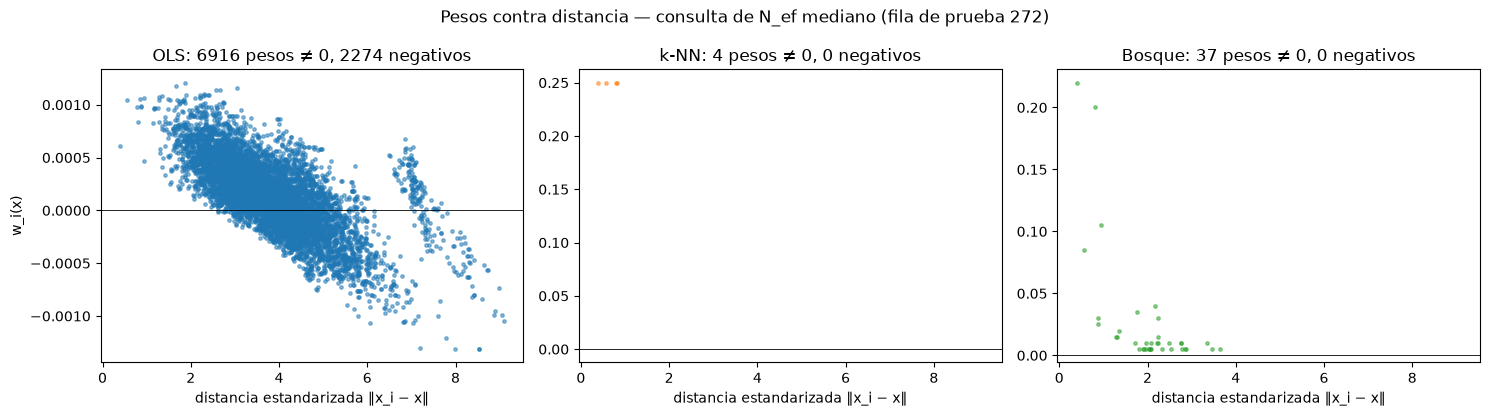

In [19]:
d = np.linalg.norm(Xb_tr - Xb_te[q], axis=1)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
for a, (nombre, color) in zip(ax, [("OLS", "C0"), ("k-NN", "C1"), ("Bosque", "C2")]):
    w = modelos_b[nombre][1](Xb_te[q:q + 1])[0]
    nz = np.abs(w) > 0
    a.scatter(d[nz], w[nz], s=6, alpha=0.5, color=color)
    a.axhline(0, color="k", lw=0.6)
    a.set_title(f"{nombre}: {nz.sum()} pesos ≠ 0, {np.sum(w < 0)} negativos")
    a.set_xlabel("distancia estandarizada ‖x_i − x‖")
ax[0].set_ylabel("w_i(x)")
fig.suptitle(f"Pesos contra distancia — consulta de N_ef mediano (fila de prueba {q})")
fig.tight_layout(); fig.savefig(f"{FIG}/2_2_pesos_vs_distancia.png", dpi=150); plt.show()

**OLS reparte pesos negativos a entre un tercio y casi la mitad de las filas** (2274–3115 de 6916 según la consulta).
Los más negativos caen en filas **muy lejanas** (percentil 96–99 de distancia): tardes con lluvia y viento
extremo (`windspeed` ≈ 0.85, el máximo de la muestra). Son puntos de alta palanca: como $w(x)$ es lineal en $x$,
OLS usa los extremos para "inclinar" el hiperplano y extrapolar, y a una fila del otro lado le toca votar en
contra. En la figura, OLS da peso positivo a las filas cercanas y negativo a las lejanas, y los pesos de mayor
magnitud (de ambos signos) están en los extremos de la nube, mientras que $k$-NN (4 pesos) y el bosque (37)
solo dejan votar a vecinos cercanos con pesos positivos.

### 2.3 ¿Sirve $N_{ef}$ para algo?

In [20]:
quint = pd.qcut(nef_rf, 5, labels=["Q1 (menos evidencia)", "Q2", "Q3", "Q4", "Q5 (más evidencia)"])
df_q = pd.DataFrame({"quintil": quint, "N_ef": nef_rf, "c(x)": conc_rf, "error abs (log)": err_rf,
                     "error abs (bicis)": np.abs(bike_te.bikers.to_numpy() - np.expm1(rf_b.predict(Xb_te))),
                     "bicis reales": bike_te.bikers.to_numpy(), "hr": bike_te.hr.to_numpy(),
                     "weathersit": bike_te.weathersit.to_numpy()})
por_q = df_q.groupby("quintil", observed=True).agg({"N_ef": ["min", "max"], "error abs (log)": "mean",
                                                    "error abs (bicis)": "mean", "bicis reales": "mean",
                                                    "hr": lambda h: np.mean((h >= 1) & (h <= 5))})
por_q.columns = ["N_ef min", "N_ef max", "MAE (log)", "MAE (bicis)", "bicis medias", "frac. madrugada 1-5h"]
por_q

,N_ef min,N_ef max,MAE (log),MAE (bicis),bicis medias,frac. madrugada 1-5h
quintil,,,,,,
Q1 (menos evidencia),1.0411,4.3299,0.2631,26.2991,153.2081,0.1387
Q2,4.3328,7.1244,0.2418,23.0202,136.5014,0.2219
Q3,7.1248,10.6284,0.2551,24.7060,136.5901,0.2355
Q4,10.6327,14.8810,0.2326,26.1050,143.4942,0.2341
Q5 (más evidencia),14.8810,48.1638,0.2624,35.9368,171.1214,0.1474


correlación de Spearman N_ef vs error abs (log): 0.03


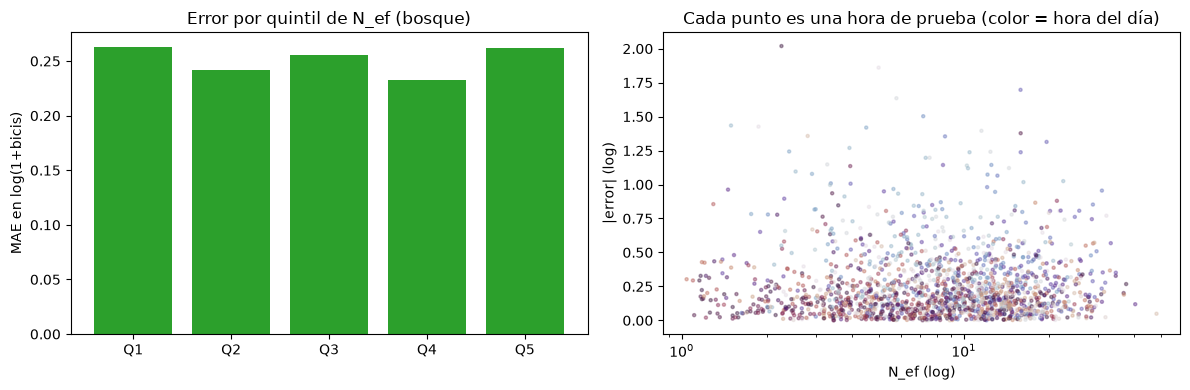

In [21]:
print("correlación de Spearman N_ef vs error abs (log):",
      df_q[["N_ef", "error abs (log)"]].corr(method="spearman").iloc[0, 1].round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(5), por_q["MAE (log)"], color="C2"); ax[0].set_xticks(range(5), [f"Q{i}" for i in range(1, 6)])
ax[0].set_ylabel("MAE en log(1+bicis)"); ax[0].set_title("Error por quintil de N_ef (bosque)")
ax[1].scatter(df_q["N_ef"], df_q["error abs (log)"], s=5, alpha=0.4, c=df_q["hr"], cmap="twilight")
ax[1].set_xscale("log"); ax[1].set_xlabel("N_ef (log)"); ax[1].set_ylabel("|error| (log)")
ax[1].set_title("Cada punto es una hora de prueba (color = hora del día)")
fig.tight_layout(); fig.savefig(f"{FIG}/2_3_error_por_quintil.png", dpi=150); plt.show()

In [22]:
# ¿Por qué? Error por hora del día y N_ef por hora
por_hora = df_q.groupby("hr").agg({"N_ef": "median", "error abs (log)": "mean", "bicis reales": "mean"})
por_hora.T.round(2)

hr,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
N_ef,10.5500,10.0400,8.1200,7.0100,8.4600,10.8100,11.9500,12.2200,10.4800,10.4700,8.0100,8.7300,6.0200,5.5500,4.8800,4.5600,7.3600,6.4700,7.5700,11.4000,10.2100,10.3700,11.4900,10.0500
error abs (log),0.2800,0.3600,0.3300,0.4800,0.4100,0.4000,0.2900,0.2800,0.4200,0.2100,0.2400,0.1800,0.1700,0.1600,0.1500,0.1600,0.1400,0.2800,0.1800,0.1700,0.1900,0.1800,0.1600,0.2600
bicis reales,43.9500,26.2100,20.1800,10.5900,5.4400,15.4300,52.7400,183.9000,281.0700,157.8700,119.8800,149.1500,183.1400,186.1800,207.0300,180.5900,227.5900,364.4100,350.9100,246.4400,178.2500,135.4700,97.7600,73.1300


**¿Las predicciones con menos evidencia se equivocan más? En nuestros datos, no.** El MAE en escala log es casi
plano entre quintiles (0.26, 0.24, 0.26, 0.23, 0.26) y la correlación de Spearman entre $N_{ef}$ y el error es 0.03.
(En bicis el Q5 se equivoca más solo porque ahí hay más bicis en promedio.) ¿Por qué?

1. **El bosque corta más fino donde la señal cambia rápido.** Con `min_samples_leaf=1` y sin bootstrap, $N_{ef}$
   mide qué tan pequeñas son las hojas. Las hojas son más pequeñas al mediodía y en las horas punta (tabla por hora:
   $N_{ef}\approx 5$ entre 12 y 15 h), justo donde la curva por hora está bien determinada y el error es bajo.
2. **El error en log lo domina el ruido de las horas con pocas bicis.** De 1 a 5 a.m. hay 5–26 bicis por hora:
   una diferencia de 3 bicis es enorme en $\log(1+y)$. Esas horas tienen $N_{ef}$ alto (8–11) y el error más alto (0.33–0.48).

$N_{ef}$ cuenta **cuántas** filas votan, no **qué tan de acuerdo** están. La varianza de un promedio es aproximadamente
$\sigma^2(x)/N_{ef}$: hace falta también $\sigma^2(x)$. El propio voto da una estimación local, la dispersión ponderada
de los testigos $\sqrt{\sum_i w_i y_i^2-\hat y^2}$:

In [23]:
media_local = W_rf_te @ yb_tr
disp_testigos = np.sqrt(np.maximum(W_rf_te @ yb_tr**2 - media_local**2, 0))
df_q["dispersión testigos"] = disp_testigos
df_q["ee aprox"] = disp_testigos / np.sqrt(nef_rf)
por_disp = df_q.groupby(pd.qcut(df_q["dispersión testigos"], 5, labels=[f"D{i}" for i in range(1, 6)]),
                        observed=True)["error abs (log)"].mean()
print("MAE (log) por quintil de dispersión de testigos:"); print(por_disp.round(3).to_string())
print("\nSpearman con el error:")
print(df_q[["N_ef", "c(x)", "dispersión testigos", "ee aprox"]].corrwith(df_q["error abs (log)"], method="spearman").round(3).to_string())
print(f"\nfracción de prueba con c(x) > 0.5: {np.mean(conc_rf > 0.5):.2f}")

MAE (log) por quintil de dispersión de testigos:
dispersión testigos
D1   0.1330
D2   0.1770
D3   0.2480
D4   0.3080
D5   0.3880

Spearman con el error:
N_ef                  0.0300
c(x)                  0.0030
dispersión testigos   0.3870
ee aprox              0.3590

fracción de prueba con c(x) > 0.5: 0.60


La dispersión de los testigos sí ordena el error: el MAE sube de forma monótona de ≈0.13 a ≈0.39 entre sus quintiles
(Spearman ≈ 0.39), mientras que $N_{ef}$ y $c(x)$ por sí solos no dicen nada (≈0.0). Además, con hojas de una fila,
el 60 % de las consultas tiene un testigo que concentra más de la mitad del voto: aquí $c(x)$ alto es la norma, no la excepción.

### 2.4 ¿Cuándo no confiar en una predicción?
Le diríamos a quien usa el modelo que **no confíe** cuando:

1. **Los testigos no están de acuerdo** (dispersión ponderada alta). Es la señal que mejor anticipa el error en
   nuestros datos; típicamente madrugadas y días de clima malo.
2. **La predicción descansa en uno o dos testigos** ($N_{ef}\lesssim 2$ o $c(x)>0.9$) **y ese testigo no se parece**
   a la consulta en las variables importantes (otra hora, otro día, otro clima). Si el testigo es la hora anterior
   del mismo día, es creíble; si es una fila de otra temporada, no. Hay que **leer la ficha**, no solo el número.
3. **Para OLS/ridge, cuando los testigos de mayor $|w_i|$ son filas lejanas con peso negativo**: el modelo está
   extrapolando, no promediando casos parecidos.
4. **Cuando los cinco modelos discrepan mucho** entre sí (la consulta del 18 de enero va de 23 a 58 bicis): es un
   indicio de que la consulta está en una región sin casos parecidos.